# Evaluation: Logistic Regression on the 200k Dataset (cmu + synthetic)

## 1. Introduction

This notebook covers steps 4 (**Evaluate**) and 5 (**Predict**) for the 200k model. It follows `05_modeling_logreg/03_evaluate` section by section, so the two models are scored in exactly the same way. In this notebook we:

1. Load the model saved by `02_train` (it is **not retrained**) and the test set, which is opened for the first time here.
2. Predict on the test set and score the model at two thresholds: the default 0.50 and the threshold chosen in `02_train`.
3. Report accuracy, precision, recall, F1 and specificity, the confusion matrix, the classification report and the ROC curve.
4. Compare training and test scores, and compare the model with the baselines.
5. Measure the uncertainty, the calibration, the per-1,000 view and the behaviour across sex and age groups.
6. Use the model on new, hypothetical respondents.

### Rules for the test set
- The test set is `diabetes_model_test`: **the same 14,039 real people as for the 70k model.** This is what makes the comparison fair. It contains **no synthetic rows**.
- The model, its features and its threshold were **fixed in `02_train`**. Nothing is changed after looking at the results here.
- If a result is disappointing, we report and discuss it. We do not tune the model on the test set.
- The training table is read **only to score the saved model on it** and to fit the baselines.

### What a believable result looks like
The cross-validation scores in `02_train` (ROC AUC about 0.81, computed on real validation people) tell us what to expect: test scores close to them. A test score clearly *above* them would be a warning sign of leakage.

**Inputs:** `logreg_200k.joblib`, `diabetes_model_test`, `diabetes_cmu_synth_train` | **Output:** a results table for the model comparison notebook

## 2. Import Libraries and Connect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from pathlib import Path

from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

# Settings (the same names and values as in 02_train)
TRAIN_TABLE = "diabetes_cmu_synth_train"
TEST_TABLE = "diabetes_model_test"
RESULTS_TABLE = "diabetes_eval_logreg_200k"
TARGET = "Diabetes_binary"
RANDOM_STATE = 42
REAL_PREVALENCE = 0.14
MODEL_PATH = Path("../../application/models/logreg_200k.joblib")

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))

print("Libraries imported and database connection successful.")

Libraries imported and database connection successful.


## 3. Load the Saved Model and the Data

Checks on the way in: the scikit-learn version, and that **no test row is identical to a training row, real or synthetic**.

In [2]:
bundle = joblib.load(MODEL_PATH)
model = bundle["model"]
FEATURES = bundle["features"]
THRESHOLD = bundle["threshold"]

train_df = pd.read_sql(f"SELECT * FROM {TRAIN_TABLE}", con=engine)
test_df = pd.read_sql(f"SELECT * FROM {TEST_TABLE}", con=engine)
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
is_real = (train_df["is_synthetic"] == 0).to_numpy()

# Leakage check: rows that appear identically in both tables (all 22 columns)
cols = list(test_df.columns)
shared = test_df.merge(train_df[cols].drop_duplicates(), how="inner")

loaded = pd.DataFrame({
    "Item": ["Saved model file", "Features used by the model", "Decision threshold from 02_train",
             "scikit-learn version (saved / current)", "Test rows", "Test: no diabetes / diabetes",
             "Training rows (read only, for scoring)", "of which synthetic",
             "Test rows identical to a training row (real or synthetic)"],
    "Value": [MODEL_PATH.name, len(FEATURES), round(THRESHOLD, 3),
              f"{bundle['sklearn_version']} / {sklearn.__version__}",
              f"{len(test_df):,}", f"{(y_test == 0).sum():,} / {(y_test == 1).sum():,}",
              f"{len(train_df):,}", f"{int(train_df['is_synthetic'].sum()):,}", len(shared)],
})
display(loaded.style.hide(axis="index"))

print("Model and data loaded successfully. The model is NOT retrained in this notebook.")

Item,Value
Saved model file,logreg_200k.joblib
Features used by the model,17
Decision threshold from 02_train,0.379000
scikit-learn version (saved / current),1.9.1 / 1.9.1
Test rows,"14,039"
Test: no diabetes / diabetes,"7,020 / 7,019"
"Training rows (read only, for scoring)","200,000"
of which synthetic,"71,922"
Test rows identical to a training row (real or synthetic),0


Model and data loaded successfully. The model is NOT retrained in this notebook.


## 4. Evaluate. Predict on the Test Set

In [3]:
proba_test = model.predict_proba(X_test)[:, 1]
proba_train = model.predict_proba(X_train)[:, 1]

chosen_label = f"Chosen ({THRESHOLD:.2f})"
thresholds_used = {"Default (0.50)": 0.5, chosen_label: THRESHOLD}
pred_test = {name: (proba_test >= t).astype(int) for name, t in thresholds_used.items()}

preview = pd.DataFrame({
    "Actual": y_test.head(5).values,
    "Probability of diabetes": proba_test[:5].round(3),
    "Predicted at default 0.50": pred_test["Default (0.50)"][:5],
    f"Predicted at {chosen_label}": pred_test[chosen_label][:5],
})
display(preview.style.hide(axis="index"))

print("Predictions on the test set completed.")

Actual,Probability of diabetes,Predicted at default 0.50,Predicted at Chosen (0.38)
0,0.107000,0,0
0,0.364000,0,0
1,0.823000,1,1
1,0.835000,1,1
0,0.270000,0,0


Predictions on the test set completed.


## 5. Accuracy, Precision, Recall and F1

The metrics are the same as in the 70k notebook. **Recall** is our main metric. Precision and accuracy are measured on balanced test data, so they are more optimistic than they would be on a real population. Recall, specificity and ROC AUC are not affected by the balance.

In [4]:
def evaluate(y, proba, threshold):
    """All metrics for one set of rows at one threshold."""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "Accuracy": accuracy_score(y, pred),
        "Recall (sensitivity)": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": tp / (tp + fp),
        "F1": f1_score(y, pred),
        "ROC AUC": roc_auc_score(y, proba),
        "Brier score": brier_score_loss(y, proba),
        "Missed diabetes cases (false negatives)": fn,
        "Healthy people flagged (false positives)": fp,
    }

results = pd.DataFrame({name: evaluate(y_test, proba_test, t) for name, t in thresholds_used.items()})

show = results.round(3).astype(object)
for r in ["Missed diabetes cases (false negatives)", "Healthy people flagged (false positives)"]:
    show.loc[r] = results.loc[r].astype(int).map("{:,}".format)
display(show)

,Default (0.50),Chosen (0.38)
Accuracy,0.726,0.726
Recall (sensitivity),0.73,0.849
Specificity,0.722,0.603
Precision,0.724,0.681
F1,0.727,0.756
ROC AUC,0.802,0.802
Brier score,0.181,0.181
Missed diabetes cases (false negatives),"1,894","1,058"
Healthy people flagged (false positives),"1,949","2,790"


**Interpretation:** At the chosen threshold (0.38) the model finds **84.9%** of the people with diabetes (Recall 0.849), so the Recall goal of 85% is met on a test set it has never seen. The price is a specificity of 0.603, a precision of 0.681 and an F1 of 0.756. At the default threshold of 0.50 the Recall is only 0.730, with a specificity of 0.722, a precision of 0.724 and an F1 of 0.727. Lowering the threshold finds 836 more people with diabetes (1,058 missed instead of 1,894) and flags 841 more healthy people (2,790 instead of 1,949), which is roughly one extra false alarm for each extra case found. Accuracy is 0.726 at both thresholds, and so is the ROC AUC (0.802) because it does not depend on the threshold, so neither can be used to choose between them. This is why Recall is our main metric. The Brier score is 0.181.

## 6. Confusion Matrix

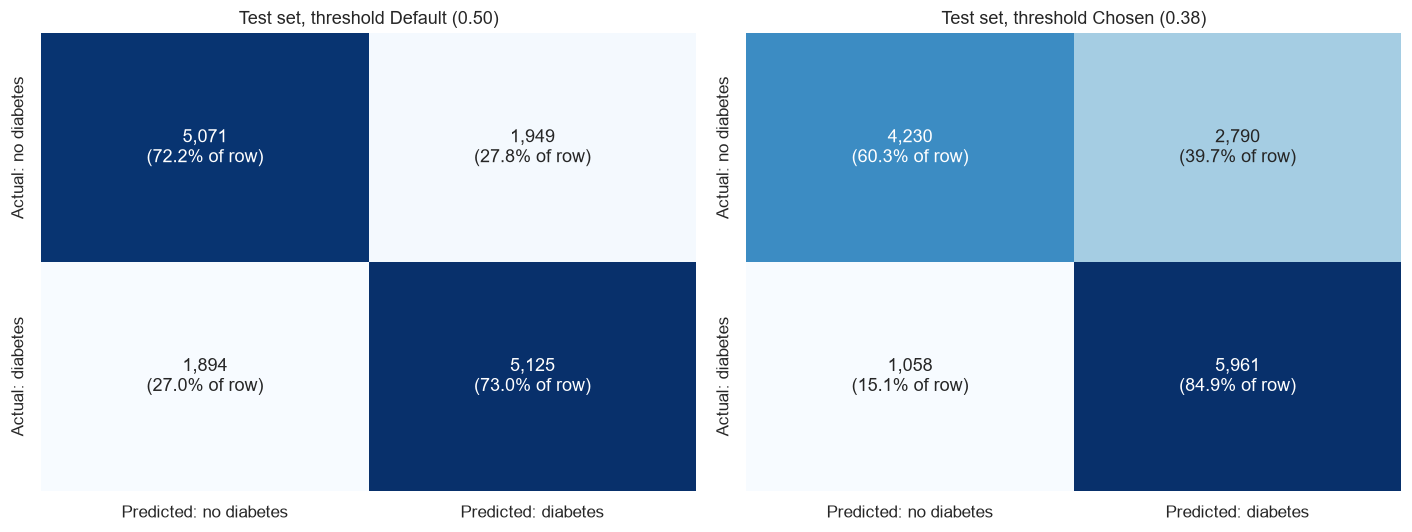

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, t) in zip(axes, thresholds_used.items()):
    cm = confusion_matrix(y_test, pred_test[name])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1f}% of row)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted: no diabetes", "Predicted: diabetes"],
                yticklabels=["Actual: no diabetes", "Actual: diabetes"])
    ax.set_title(f"Test set, threshold {name}")
plt.tight_layout()
plt.show()

**Interpretation:** At the default threshold the model correctly identifies 5,125 of 7,019 people with diabetes (73.0%) and 5,071 of 7,020 people without (72.2%), so it makes about the same share of mistakes in both groups: 1,894 missed cases and 1,949 false alarms. At the chosen threshold the picture changes on purpose: 5,961 people with diabetes are found (84.9%) and only 1,058 are missed (15.1%), while 4,230 healthy people are correctly cleared (60.3%) and 2,790 are flagged (39.7%). The missed cases drop by 44%, and the false alarms rise by 43%.

## 7. Classification Report

In [6]:
for name in thresholds_used:
    report = pd.DataFrame(classification_report(
        y_test, pred_test[name], target_names=["No diabetes", "Diabetes"], output_dict=True)).T
    print(f"Classification report, threshold {name}:")
    display(report.round(3))

Classification report, threshold Default (0.50):


,precision,recall,f1-score,support
No diabetes,0.728,0.722,0.725,7020.000
Diabetes,0.724,0.730,0.727,7019.000
accuracy,0.726,0.726,0.726,0.726
macro avg,0.726,0.726,0.726,14039.000
weighted avg,0.726,0.726,0.726,14039.000


Classification report, threshold Chosen (0.38):


,precision,recall,f1-score,support
No diabetes,0.800,0.603,0.687,7020.000
Diabetes,0.681,0.849,0.756,7019.000
accuracy,0.726,0.726,0.726,0.726
macro avg,0.741,0.726,0.722,14039.000
weighted avg,0.741,0.726,0.722,14039.000


**Interpretation:** With the default threshold the two classes look the same (precision 0.728 and 0.724, recall 0.722 and 0.730), so the model is balanced. At the chosen threshold the classes become different: for *Diabetes* recall rises to 0.849 and precision falls to 0.681, for *No diabetes* recall falls to 0.603 and precision rises to 0.800. The 0.800 means that when the model clears someone, it is right 80% of the time. The accuracy stays at 0.726. The two classes have almost the same number of people (7,020 and 7,019), so the macro and weighted averages are identical.

## 8. ROC Curve and ROC AUC

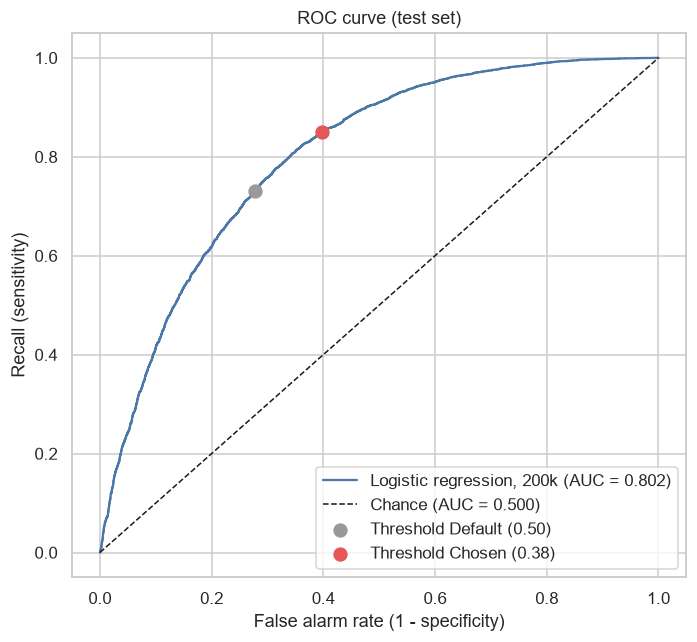

ROC AUC on the test set: 0.802


In [7]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc = roc_auc_score(y_test, proba_test)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color="#4C78A8", label=f"Logistic regression, 200k (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.500)")
for (name, t), color in zip(thresholds_used.items(), ["#999999", "#E45756"]):
    m = results[name]
    ax.scatter(1 - m["Specificity"], m["Recall (sensitivity)"], s=70, color=color, zorder=3,
               label=f"Threshold {name}")
ax.set_xlabel("False alarm rate (1 - specificity)")
ax.set_ylabel("Recall (sensitivity)")
ax.set_title("ROC curve (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"ROC AUC on the test set: {auc:.3f}")

**Interpretation:** The ROC AUC on the test set is **0.802**. If we pick one person with diabetes and one without at random, the model gives the higher score to the person with diabetes 80% of the time. The curve is clearly above the diagonal (chance, 0.500). The two thresholds are just two points on the same curve: the grey point (0.50) has a lower recall and a lower false alarm rate, and the red point (0.38) has a higher recall and a higher false alarm rate. Changing the threshold moves us along the curve, it does not make the model better. The cross-validation ROC AUC in `02_train` was 0.808, which is only 0.006 higher and inside the confidence interval of the test score (section 11), so the test result is what we expected and there is no sign of leakage.

## 9. Training Score Against Test Score

The professor's rule: report **both**. Here the training score is shown in two versions:

- **All 200,000 rows:** includes the synthetic rows. It is optimistic, because synthetic rows are interpolations of the real diabetes people and are easier to fit than real people.
- **Real rows only:** the fair version. The training rows are 100,000 no-diabetes rows and 28,078 diabetes rows, so only Recall, specificity and ROC AUC are directly comparable with the test set. Accuracy, precision and F1 are computed on a 50/50 scale from Recall and specificity for this version.

In [8]:
def scores_5050(y, proba, t):
    """Same metrics, with precision/F1/accuracy on a 50/50 scale (for the unbalanced real training rows)."""
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    tpr, tnr = tp / (tp + fn), tn / (tn + fp)
    prec = tpr / (tpr + (1 - tnr))
    return {"Accuracy": (tpr + tnr) / 2, "Recall (sensitivity)": tpr, "Precision": prec,
            "F1": 2 * prec * tpr / (prec + tpr), "ROC AUC": roc_auc_score(y, proba)}

metrics_to_compare = ["Accuracy", "Recall (sensitivity)", "Precision", "F1", "ROC AUC"]

rows = {}
for name, t in thresholds_used.items():
    train_all = evaluate(y_train, proba_train, t)
    train_real = scores_5050(y_train[is_real], proba_train[is_real], t)
    test_res = evaluate(y_test, proba_test, t)
    for metric in metrics_to_compare:
        rows.setdefault(metric, {})[f"Train (all 200k), {name}"] = train_all[metric]
        rows[metric][f"Train (real rows), {name}"] = train_real[metric]
        rows[metric][f"Test, {name}"] = test_res[metric]

gap_df = pd.DataFrame(rows).T
display(gap_df.round(3))

gaps = {m: gap_df.loc[m, f"Train (real rows), {chosen_label}"] - gap_df.loc[m, f"Test, {chosen_label}"]
        for m in gap_df.index}
print(f"Largest gap between the training (real rows) and test score at the chosen threshold: "
      f"{max(gaps.values(), key=abs):+.4f}")

,"Train (all 200k), Default (0.50)","Train (real rows), Default (0.50)","Test, Default (0.50)","Train (all 200k), Chosen (0.38)","Train (real rows), Chosen (0.38)","Test, Chosen (0.38)"
Accuracy,0.746,0.732,0.726,0.738,0.730,0.726
Recall (sensitivity),0.766,0.738,0.730,0.869,0.851,0.849
Precision,0.737,0.730,0.724,0.689,0.685,0.681
F1,0.751,0.734,0.727,0.769,0.759,0.756
ROC AUC,0.823,0.808,0.802,0.823,0.808,0.802


Largest gap between the training (real rows) and test score at the chosen threshold: +0.0061


**Interpretation:** At the chosen threshold the scores on the real training rows and on the test set are very close: ROC AUC 0.808 against 0.802, Recall 0.851 against 0.849, Precision 0.685 against 0.681, F1 0.759 against 0.756 and accuracy 0.730 against 0.726. The largest gap is +0.0061 (ROC AUC), so there is **no overfitting**. The training score on all 200,000 rows is higher (ROC AUC 0.823, Recall 0.869), by about 2 points of Recall, because the synthetic rows are easier to fit than real people. This is why we compare with the real rows only: comparing with the 200,000-row column would make the test score look worse than it is. A test score slightly below the training score is normal, since the test people were never seen.

## 10. Logistic Regression Against the Baselines (Test Set)

In [9]:
baselines = {
    "Baseline: always no diabetes": DummyClassifier(strategy="constant", constant=0),
    "Baseline: flag everybody": DummyClassifier(strategy="constant", constant=1),
    "Baseline: random guess": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

comparison = {}
for name, m in baselines.items():
    m.fit(X_train, y_train)
    pred, proba = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    comparison[name] = {"Accuracy": accuracy_score(y_test, pred), "Recall": recall_score(y_test, pred),
                        "Precision": precision_score(y_test, pred, zero_division=0),
                        "F1": f1_score(y_test, pred, zero_division=0), "ROC AUC": roc_auc_score(y_test, proba)}

for name in thresholds_used:
    r = results[name]
    comparison[f"Logistic regression, threshold {name}"] = {
        "Accuracy": r["Accuracy"], "Recall": r["Recall (sensitivity)"], "Precision": r["Precision"],
        "F1": r["F1"], "ROC AUC": r["ROC AUC"]}

display(pd.DataFrame(comparison).T.round(3))

,Accuracy,Recall,Precision,F1,ROC AUC
Baseline: always no diabetes,0.500,0.000,0.000,0.000,0.500
Baseline: flag everybody,0.500,1.000,0.500,0.667,0.500
Baseline: random guess,0.499,0.505,0.499,0.502,0.499
"Logistic regression, threshold Default (0.50)",0.726,0.730,0.724,0.727,0.802
"Logistic regression, threshold Chosen (0.38)",0.726,0.849,0.681,0.756,0.802


**Interpretation:** All three baselines are at chance on the test set (ROC AUC 0.500, 0.500 and 0.499, accuracy 0.500, 0.500 and 0.499). The logistic regression is clearly better, with a ROC AUC of 0.802 and an accuracy of 0.726. *Flag everybody* has a Recall of 1.000, which is higher than the model's, but its precision is only 0.500, so it is useless as a screening tool. Its F1 of 0.667 is also lower than the model's F1 (0.727 at the default threshold and 0.756 at the chosen one).

## 11. How Certain Are These Results?

Bootstrap: 1,000 new samples of the test rows (with replacement), metrics recomputed each time, 95% confidence interval from the middle 95%. The intervals are for the chosen threshold. **These intervals are needed for `08_model_comparison`**: if the 70k and 200k intervals overlap heavily, the two models are not clearly different.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr, p_arr = y_test.to_numpy(), proba_test
n = len(y_arr)

boot = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    yb, pb = y_arr[idx], p_arr[idx]
    tn, fp, fn, tp = confusion_matrix(yb, (pb >= THRESHOLD).astype(int)).ravel()
    boot.append({"Recall": tp / (tp + fn), "Specificity": tn / (tn + fp),
                 "Precision": tp / (tp + fp), "ROC AUC": roc_auc_score(yb, pb)})
boot = pd.DataFrame(boot)

point = results[chosen_label]
ci = pd.DataFrame({
    "Estimate": [point["Recall (sensitivity)"], point["Specificity"], point["Precision"], point["ROC AUC"]],
    "95% CI low": boot.quantile(0.025).values,
    "95% CI high": boot.quantile(0.975).values,
}, index=["Recall", "Specificity", "Precision", "ROC AUC"])
display(ci.round(3))

,Estimate,95% CI low,95% CI high
Recall,0.849,0.841,0.858
Specificity,0.603,0.590,0.614
Precision,0.681,0.671,0.691
ROC AUC,0.802,0.795,0.810


**Interpretation:** With 14,039 test people the intervals are narrow, about plus or minus 1 point: Recall 0.849 (0.841 to 0.858), Specificity 0.603 (0.590 to 0.614), Precision 0.681 (0.671 to 0.691) and ROC AUC 0.802 (0.795 to 0.810). The Recall goal of 85% lies inside the Recall interval, so we can say the goal is met. The cross-validation values from `02_train` (Recall 0.850, ROC AUC 0.808) also lie inside the intervals. For `08_model_comparison` this means that a difference of less than about 1.5 points between the 70k and 200k models should not be called a real difference.

## 12. Can the Probabilities Be Trusted? (Calibration)

The model was trained on 50/50 data, so these probabilities are on a **balanced scale**.

,Mean predicted probability,Share who actually have diabetes
Group 1,0.059,0.044
Group 2,0.147,0.142
Group 3,0.243,0.280
Group 4,0.350,0.389
Group 5,0.455,0.512
Group 6,0.554,0.594
Group 7,0.643,0.652
Group 8,0.731,0.751
Group 9,0.815,0.785
Group 10,0.910,0.850


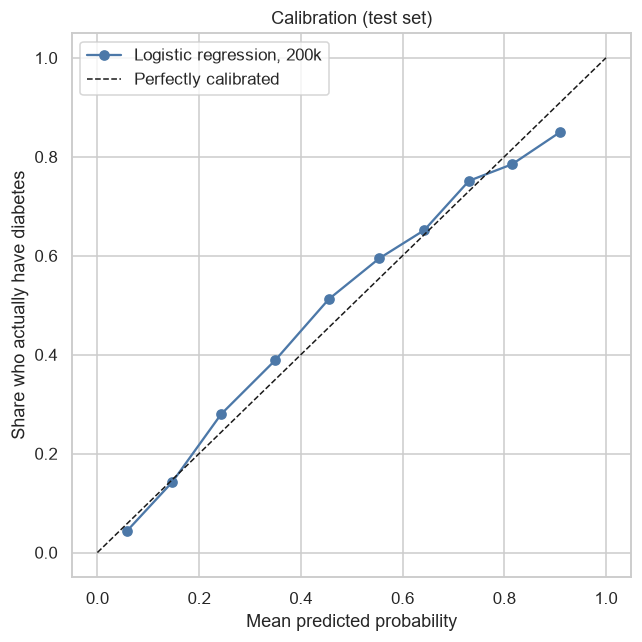

Brier score: 0.181


In [11]:
frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")

calib = pd.DataFrame({"Mean predicted probability": mean_pred,
                      "Share who actually have diabetes": frac_pos})
calib.index = [f"Group {i}" for i in range(1, len(calib) + 1)]
display(calib.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(mean_pred, frac_pos, marker="o", color="#4C78A8", label="Logistic regression, 200k")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Share who actually have diabetes")
ax.set_title("Calibration (test set)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Brier score: {brier_score_loss(y_test, proba_test):.3f}")

**Interpretation:** The probabilities are roughly trustworthy but not perfect. In the middle groups the share of people who really have diabetes is 4 to 6 points higher than predicted (Group 3: 0.243 predicted, 0.280 actual; Group 5: 0.455 and 0.512; Group 6: 0.554 and 0.594). In the highest groups the model is over-confident (Group 10: 0.910 predicted, 0.850 actual; Group 9: 0.815 and 0.785), and Group 1 is slightly over-estimated (0.059 and 0.044). The calibration curve is therefore a little flatter than the diagonal. The Brier score of 0.181 is clearly better than the 0.25 that a model always predicting 0.5 would get on balanced data. The differences are never more than about 6 points, so the scores are good for ranking people and for choosing a threshold. Remember that this is on the balanced scale (50% diabetes), so the app converts the probability to the real prevalence of about 14% before showing it.

## 13. What the Threshold Means in Practice (Per 1,000 People Screened)

In [12]:
rows = []
for name, t in thresholds_used.items():
    m = results[name]
    tpr, false_alarm_rate = m["Recall (sensitivity)"], 1 - m["Specificity"]
    n_pos = 1000 * REAL_PREVALENCE
    n_neg = 1000 - n_pos
    found = n_pos * tpr
    flagged_healthy = n_neg * false_alarm_rate
    rows.append({
        "Threshold": name,
        "Have diabetes": n_pos,
        "Found": found,
        "Missed": n_pos - found,
        "Healthy people flagged": flagged_healthy,
        "Total flagged": found + flagged_healthy,
        "Share with diabetes among those flagged": found / (found + flagged_healthy),
    })
display(pd.DataFrame(rows).round(2).style.hide(axis="index"))

Threshold,Have diabetes,Found,Missed,Healthy people flagged,Total flagged,Share with diabetes among those flagged
Default (0.50),140.000000,102.220000,37.780000,238.770000,340.990000,0.300000
Chosen (0.38),140.000000,118.900000,21.100000,341.790000,460.690000,0.260000


**Interpretation:** Out of 1,000 people (140 with diabetes) the default threshold finds about 102 and misses 38, and flags 239 healthy people. The chosen threshold finds about 119 and misses 21, and flags 342 healthy people. So the extra 17 cases found cost about 103 more healthy people flagged, roughly 6 extra false alarms for every extra case found. At the chosen threshold 461 people out of 1,000 are flagged and only 26% of them (about 1 in 4) really have diabetes, so 3 out of 4 flagged people do not. This is an acceptable price only because the follow-up is a simple blood test. These numbers use the real prevalence of 14%, so they are an approximation, because the labels are self-reported diagnoses.

## 14. Does the Model Work Equally Well for Different Groups?

In [13]:
test_all = test_df.copy()
test_all["proba"] = proba_test
test_all["pred"] = (proba_test >= THRESHOLD).astype(int)
test_all["Age group"] = pd.cut(test_all["Age"], bins=[0, 5, 9, 13],
                               labels=["18-44 (codes 1-5)", "45-64 (codes 6-9)", "65+ (codes 10-13)"])
test_all["Sex group"] = test_all["Sex"].map({0: "Female", 1: "Male"})

rows = []
for col in ["Sex group", "Age group"]:
    for level, g in test_all.groupby(col, observed=True):
        tn, fp, fn, tp = confusion_matrix(g[TARGET], g["pred"], labels=[0, 1]).ravel()
        rows.append({
            "Group": f"{col.replace(' group', '')}: {level}",
            "People": len(g),
            "% with diabetes": g[TARGET].mean() * 100,
            "Recall": tp / (tp + fn) if (tp + fn) else np.nan,
            "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "ROC AUC": roc_auc_score(g[TARGET], g["proba"]) if g[TARGET].nunique() == 2 else np.nan,
        })
display(pd.DataFrame(rows).round(3).style.hide(axis="index"))

Group,People,% with diabetes,Recall,Specificity,ROC AUC
Sex: Female,7644,48.325000,0.848000,0.638000,0.818000
Sex: Male,6395,51.994000,0.851000,0.557000,0.781000
Age: 18-44 (codes 1-5),2153,21.366000,0.596000,0.876000,0.830000
Age: 45-64 (codes 6-9),5977,49.189000,0.819000,0.618000,0.791000
Age: 65+ (codes 10-13),5909,61.246000,0.906000,0.379000,0.741000


**Interpretation:** Recall is the same for women (0.848) and men (0.851), but men get more false alarms (specificity 0.557 against 0.638), and the ROC AUC is lower for men (0.781 against 0.818). The big differences are by age. Recall rises from 0.596 for ages 18 to 44, to 0.819 for 45 to 64, and 0.906 for 65 and over, while specificity falls from 0.876 to 0.618 to 0.379. So the single threshold behaves partly like an age screen: it misses about 4 in 10 younger people with diabetes and flags 6 in 10 healthy people aged 65 and over. The ROC AUC is also lower in the oldest group (0.741 against 0.830), because older people are all similar in risk factors and are harder to separate. The overall Recall of 85% is therefore **not met for the 18-44 group**, which has only 2,153 people (about 460 with diabetes), so that estimate is also less certain. This is a limitation to report, and it is one more reason for the app to say that a low-risk result is not a guarantee.

## 15. Predict. Using the Model on New People

The same three hypothetical respondents as in the 70k notebook, so the two models' outputs can be compared person by person.

In [14]:
def adjust_probability(p, prevalence=REAL_PREVALENCE):
    """Convert a probability from the balanced (50/50) scale to the real prevalence."""
    odds = p / (1 - p) * (prevalence / (1 - prevalence))
    return odds / (1 + odds)

def predict_risk(answers):
    row = pd.DataFrame([answers])[FEATURES]
    p = float(model.predict_proba(row)[:, 1][0])
    return {
        "Model probability (balanced data)": p,
        f"Adjusted to {REAL_PREVALENCE:.0%} prevalence": adjust_probability(p),
        "Flagged for follow-up": p >= THRESHOLD,
    }

people = {
    "Person A: 32 years old, healthy": {
        "HighBP": 0, "HighChol": 0, "CholCheck": 1, "BMI": 23, "Smoker": 0, "Stroke": 0,
        "HeartDiseaseorAttack": 0, "PhysActivity": 1, "Fruits": 1, "Veggies": 1, "HvyAlcoholConsump": 0,
        "AnyHealthcare": 1, "NoDocbcCost": 0, "GenHlth": 1, "MentHlth": 0, "PhysHlth": 0, "DiffWalk": 0,
        "Sex": 0, "Age": 3, "Education": 6, "Income": 7},
    "Person B: 57 years old, some risk factors": {
        "HighBP": 1, "HighChol": 0, "CholCheck": 1, "BMI": 31, "Smoker": 1, "Stroke": 0,
        "HeartDiseaseorAttack": 0, "PhysActivity": 1, "Fruits": 0, "Veggies": 1, "HvyAlcoholConsump": 0,
        "AnyHealthcare": 1, "NoDocbcCost": 0, "GenHlth": 3, "MentHlth": 2, "PhysHlth": 3, "DiffWalk": 0,
        "Sex": 1, "Age": 8, "Education": 4, "Income": 5},
    "Person C: 72 years old, several risk factors": {
        "HighBP": 1, "HighChol": 1, "CholCheck": 1, "BMI": 38, "Smoker": 0, "Stroke": 0,
        "HeartDiseaseorAttack": 1, "PhysActivity": 0, "Fruits": 0, "Veggies": 0, "HvyAlcoholConsump": 0,
        "AnyHealthcare": 1, "NoDocbcCost": 1, "GenHlth": 4, "MentHlth": 5, "PhysHlth": 15, "DiffWalk": 1,
        "Sex": 1, "Age": 11, "Education": 3, "Income": 2},
}
display(pd.DataFrame({name: predict_risk(a) for name, a in people.items()}).T.round(3))

,Model probability (balanced data),Adjusted to 14% prevalence,Flagged for follow-up
"Person A: 32 years old, healthy",0.031868,0.00533,False
"Person B: 57 years old, some risk factors",0.552131,0.167144,True
"Person C: 72 years old, several risk factors",0.944157,0.733499,True


**Interpretation:** The three people are ordered as expected. Person A (32, healthy) gets a probability of 0.032, which is 0.5% after adjusting to the real prevalence, and is not flagged. Person B (57, some risk factors) gets 0.552, adjusted to 16.7%, and is flagged. Person C (72, several risk factors) gets 0.944, adjusted to 73.3%, and is flagged. The raw and adjusted numbers differ a lot: Person B looks like a 55% risk on the balanced scale but is about 17% at the real prevalence, which is why the app shows the adjusted value. The threshold of 0.379 is the same as an adjusted chance of about 9%, which is *lower* than the average of 14%. This is deliberate: to reach 85% Recall we also have to flag people whose risk is only a little above average. The comparison with the 70k model for the same three people is done in `08_model_comparison`.

## 16. Save the Results

In [15]:
out = results.T.reset_index().rename(columns={"index": "Threshold"})
out.insert(0, "Model", "Logistic regression (200k: real + synthetic)")
out.to_sql(RESULTS_TABLE, con=engine, if_exists="replace", index=False)

with engine.connect() as conn:
    saved_rows = conn.execute(text(f"SELECT COUNT(*) FROM {RESULTS_TABLE}")).scalar()

print(f"Results saved: {saved_rows} rows in '{RESULTS_TABLE}'.")

Results saved: 2 rows in 'diabetes_eval_logreg_200k'.


## 17. Summary

**What we did in this notebook**
1. Loaded the model saved in `02_train` (not retrained) and opened the real test set (14,039 rows, the same as for the 70k model).
2. Scored the model at the default threshold (0.50) and at the chosen threshold (0.38).
3. Reported accuracy, precision, recall, F1, specificity, the confusion matrix, the classification report and the ROC curve.
4. Compared training and test scores, and compared the model with the baselines.
5. Measured the uncertainty, checked calibration, translated the threshold to a per-1,000 view, and checked sex and age groups.
6. Used the model on three hypothetical respondents and saved the results for the model comparison.

**Key results (test set, chosen threshold)**
- **Recall:** 0.849 (95% CI 0.841 to 0.858). **Specificity:** 0.603. **Precision:** 0.681. **F1:** 0.756.
- **ROC AUC:** 0.802 (95% CI 0.795 to 0.810). **Accuracy:** 0.726.
- **At the default threshold (0.50):** Recall 0.730, precision 0.724.
- **Training vs test:** the largest gap (real training rows) is +0.0061 (ROC AUC), so there is no overfitting.
- **Baselines:** the model beats all three (ROC AUC 0.802 against 0.50).
- **Per 1,000 people screened (14% prevalence):** about 461 flagged, 119 found, 21 missed, 342 healthy people flagged.
- **Calibration:** roughly right (4 to 6 points too low in the middle groups, up to 6 points too high at the top) (Brier score 0.181).
- **Groups:** Recall is equal for women and men, but depends strongly on age (0.596 for 18-44, 0.819 for 45-64, 0.906 for 65+), so the 85% goal is not met in the youngest group.

**For `08_model_comparison`**
- 70k model against 200k model on the **same** test set: ROC AUC 0.802 (200k) against [70k value from the 05 evaluate notebook]; Recall at the chosen threshold 0.849 (200k) against [70k value from the 05 evaluate notebook]. Do the 95% confidence intervals overlap? [compare with the 70k intervals from the 05 notebook]
- Remember that the 200k model has the *same real diabetes people* as the 70k model; the extra 100,000 rows are 71,922 synthetic diabetes rows and 71,923 more real no-diabetes rows. Any difference comes from those.

**Limitations**
- All answers are self-reported, and the target is a *diagnosed* condition.
- Precision and accuracy are measured on balanced data and are optimistic. The per-1,000 view is an approximation.
- The model's raw probability is on a balanced scale. The app should show a flag or the adjusted probability.
- About 72% of the diabetes class in training is synthetic (see `01_prepare_synthetic`).

**Next step:** `08_model_comparison`.